# **Лабораторная 2. Неиерархический кластерный анализ, классификация**

> - **Предмет**: Математические методы анализа экономических процессов
> - **Студент**: Руденко Андрей Артемович
> - **Группа**: М9125-01.04.02МКТ

## Цель работы
1. Провести пошаговую кластеризацию набора данных методом k-средних
2. Выполнить неиерархическую кластеризацию и классификацию набора данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

## 2.1. Пошаговая кластеризация набора данных

### Данные *(Вариант 16)*

Однокомнатные квартиры в 13 районах города: X1 — площадь комнаты, м², X2 — цена квартиры, тыс. USD.

In [2]:
data = pd.DataFrame({'X1': [12, 12, 19, 15, 19, 15, 19, 19.8, 19, 21.5, 14, 22, 19],
                     'X2': [31, 37, 43, 38, 51, 30, 30, 36, 33, 35, 28, 40, 33]}, index=range(1, 14))
data.columns.name = 'Район'
data

Район,X1,X2
1,12.0,31
2,12.0,37
3,19.0,43
4,15.0,38
5,19.0,51
6,15.0,30
7,19.0,30
8,19.8,36
9,19.0,33
10,21.5,35


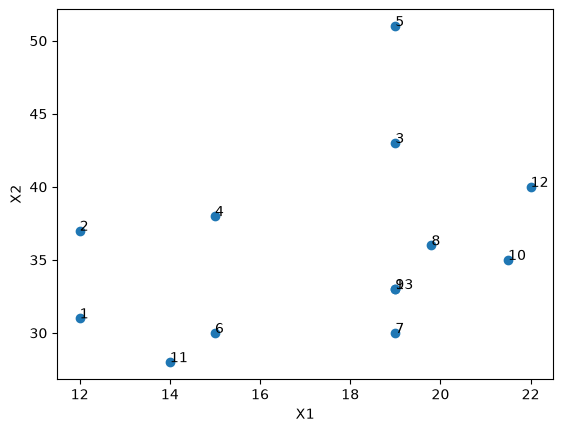

In [3]:
plt.scatter(data['X1'], data['X2'])
for i in data.index:
    plt.text(data['X1'][i], data['X2'][i], i)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

### Число кластеров

На диаграмме рассеяния видны 3 группы районов: с маленькой комнатой (1, 2, 4, 6, 11), с большой комнатой и средней ценой (7, 8, 9, 10, 12, 13) и с высокой ценой (3, 5). Поэтому беру 3 кластера.

### Метрика расстояния

Использую евклидово расстояние, т.к. оба признака числовые.
$$d(x, c) = \sqrt{(X1_x - X1_c)^2 + (X2_x - X2_c)^2}$$

In [4]:
def euclid(p, q):
    return np.sqrt(((p - q) ** 2).sum())

### Метод k-средних

Каждый объект относится к кластеру с ближайшим центром, затем центр пересчитывается как среднее объектов кластера. Шаги повторяются, пока распределение объектов по кластерам не перестанет меняться.
$$k(x) = \arg\min_k d(x, c_k), \qquad c_k = \frac{1}{|C_k|} \sum_{x \in C_k} x$$

In [5]:
def kmeans(df, start):
    centers = df.loc[start]
    centers.index = range(1, len(start) + 1)
    labels = None
    step = 1
    while True:
        new_labels = pd.Series({i: min(centers.index, key=lambda c: euclid(df.loc[i], centers.loc[c])) for i in df.index})
        print(f'Шаг: {step}')
        print(centers.round(2))
        print({c: list(new_labels[new_labels == c].index) for c in centers.index})
        if labels is not None and (new_labels == labels).all():
            return labels
        labels = new_labels
        centers = df.groupby(labels).mean()
        step += 1


def plot_clusters(labels):
    plt.scatter(data['X1'], data['X2'], c=labels, cmap='tab10')
    for i in data.index:
        plt.text(data['X1'][i], data['X2'][i], i)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.show()

### Кластеризация исходных данных

Начальные центры — районы 1, 10 и 5, по одному из каждой группы на диаграмме рассеяния.

Шаг: 1
Район    X1  X2
1      12.0  31
2      21.5  35
3      19.0  51
{1: [1, 2, 6, 11], 2: [4, 7, 8, 9, 10, 12, 13], 3: [3, 5]}
Шаг: 2
Район     X1    X2
1      13.25  31.5
2      19.33  35.0
3      19.00  47.0
{1: [1, 2, 6, 11], 2: [4, 7, 8, 9, 10, 12, 13], 3: [3, 5]}


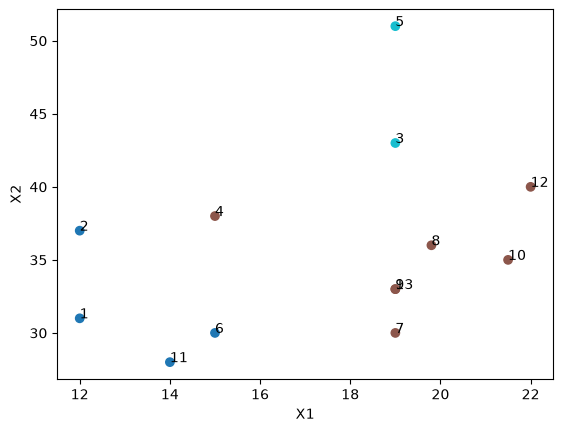

In [6]:
labels_raw = kmeans(data, [1, 10, 5])
plot_clusters(labels_raw)

### Кластеризация стандартизованных данных

Стандартизация приводит признаки к среднему 0 и стандартному отклонению 1, чтобы оба признака одинаково влияли на расстояние.
$$z = \frac{x - \bar{x}}{\sigma}$$

Шаг: 1
Район    X1    X2
1     -1.60 -0.76
2      1.21 -0.12
3      0.47  2.42
{1: [1, 2, 4, 6, 11], 2: [7, 8, 9, 10, 12, 13], 3: [3, 5]}
Шаг: 2
Район    X1    X2
1     -1.12 -0.47
2      0.78 -0.20
3      0.47  1.79
{1: [1, 2, 4, 6, 11], 2: [7, 8, 9, 10, 12, 13], 3: [3, 5]}


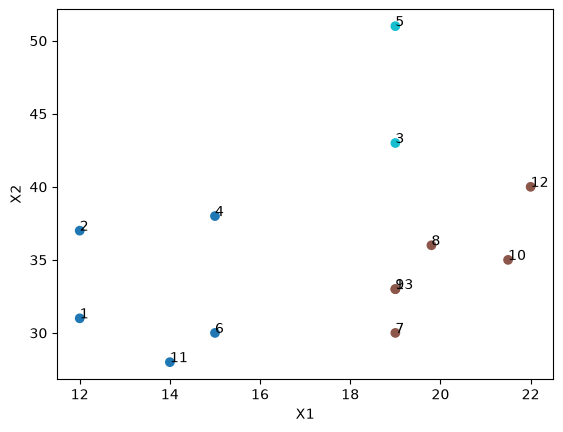

In [7]:
scaled = (data - data.mean()) / data.std()
labels_scaled = kmeans(scaled, [1, 10, 5])
plot_clusters(labels_scaled)

### Результат

На исходных данных алгоритм сошёлся за 2 шага, но район 4 попал в кластер районов с большой комнатой, хотя на диаграмме он ближе к району 2. Разброс цены (от 28 до 51) больше разброса площади (от 12 до 22), поэтому цена сильнее влияет на расстояние.

После стандартизации оба признака влияют на расстояние одинаково, и кластеры совпали с группами на диаграмме: {1, 2, 4, 6, 11}, {7, 8, 9, 10, 12, 13} и {3, 5}.

## 2.2. Неиерархическая кластеризация и классификация

### Данные *(Вариант 16)*

Число социально ориентированных НКО по видам деятельности за 2012–2020 гг. Строка «Всего» — сумма остальных строк, поэтому её исключаю. Пропуски — годы, когда вид деятельности ещё не учитывался, — заменяю средним по строке.

In [8]:
nko = pd.read_csv('16.csv', encoding='cp1251', header=1, index_col=0, dtype=str)
nko = nko.dropna(how='all').drop(index='Всего')
nko = nko.apply(lambda col: pd.to_numeric(col.str.replace(',', '').str.strip(), errors='coerce'))
for i in nko.index:
    nko.loc[i] = nko.loc[i].fillna(nko.loc[i].mean())

names = pd.Series(nko.index, index=range(1, len(nko) + 1))
nko.index = names.index
years = list(nko.columns)
nko

,2012,2013,2014,2015,2016,2017,2018,2019,2020
1,8678.000000,8664.000000,10231.000000,8683.0,4476,4454,4630,5133,5021
2,9301.000000,9491.000000,11030.000000,9587.0,6073,6003,6086,6456,5861
3,9383.000000,9631.000000,11243.000000,9818.0,6659,6651,6536,6776,6194
4,19557.000000,19743.000000,19692.000000,18616.0,18269,17648,17000,16973,14756
5,1874.000000,2031.000000,3464.000000,3284.0,2139,2156,2243,2367,2201
6,2804.000000,3137.000000,5171.000000,4742.0,2732,2620,2600,2576,1885
7,4263.000000,4424.000000,4041.000000,4005.0,4776,4930,5025,5601,5354
8,2170.000000,2305.000000,2166.000000,2109.0,1818,1792,1811,1955,1595
9,7750.000000,7492.000000,7718.000000,7504.0,9455,9098,8618,8563,7584
10,4059.000000,3555.000000,3997.000000,3526.0,3295,3205,3075,2993,2797


### Число кластеров

Число кластеров выбираю методом локтя: строю сумму квадратов расстояний от объектов до центров их кластеров (WSS) для разного числа кластеров и ищу точку, после которой она убывает медленно.

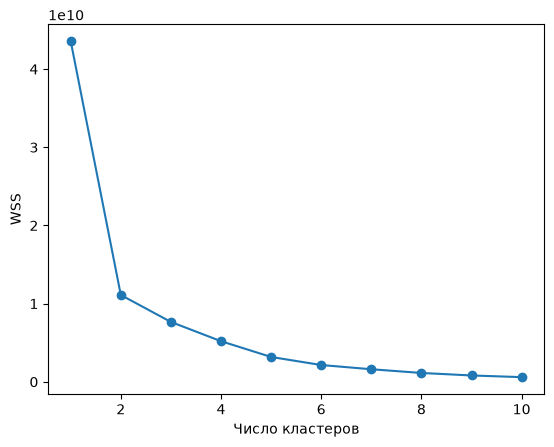

In [9]:
wss = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(nko[years]).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), wss, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('WSS')
plt.show()

Самый резкий излом — при 2 кластерах, но 2 кластера только отделяют крупные виды деятельности от мелких. Беру 3 кластера: после них WSS убывает плавно.

### Кластеризация методом k-средних

In [10]:
k = 3
kmeans_nko = KMeans(n_clusters=k, n_init=10, random_state=42).fit(nko[years])
nko['cluster'] = kmeans_nko.labels_ + 1

total_ss = ((nko[years] - nko[years].mean()) ** 2).sum().sum()
print(f'between_SS / total_SS = {(total_ss - kmeans_nko.inertia_) / total_ss:.1%}')
nko['cluster'].value_counts().sort_index()

between_SS / total_SS = 82.4%


cluster
1     3
2    22
3     7
Name: count, dtype: int64

In [11]:
for c in range(1, k + 1):
    print(f'Кластер {c}:')
    for i in nko.index[nko['cluster'] == c]:
        print(f'  {i}. {names[i]}')

Кластер 1:
  4. другие виды социальной поддержки и защиты граждан
  12. благотворительная деятельность
  32. оказание социальных услуг населению Российской Федерации в сферах деятельности социально ориентированных некоммерческих организаций
Кластер 2:
  1. профилактика социально сиротства, поддержка материнства и детства
  2. повышение качества жизни людей пожилого возраста
  3. социальная адаптация инвалидов и их семей
  5. подготовка населения в области защиты от чрезвычайных ситуаций
  6. оказание помощи пострадавшим в результате стихийных бедствий, экологических, техногенных или иных катастроф
  7. охрана окружающей среды и защита животных
  8. охрана и содержание объектов и территорий, имеющих историческое, культовое, культурное или природоохранное значение, и мест захоронений
  9. оказание юридической помощи на безвозмездной или на льготной основе гражданам, правовое просвещение населения, деятельность по защите прав и свобод человека и гражданина
  10. оказание юридической помощ

In [12]:
nko.groupby('cluster')[years].mean().round(0)

,2012,2013,2014,2015,2016,2017,2018,2019,2020
cluster,,,,,,,,,
1,18140.0,18517.0,19296.0,19163.0,14770.0,19564.0,19988.0,20524.0,18227.0
2,3692.0,3831.0,6113.0,5891.0,4107.0,4023.0,3963.0,4127.0,3715.0
3,25438.0,26100.0,49493.0,50657.0,23210.0,22331.0,21388.0,21816.0,18137.0


### Диаграмма рассеяния

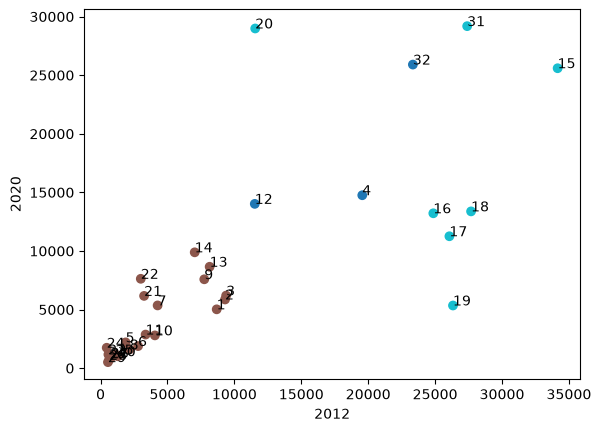

In [13]:
plt.scatter(nko['2012'], nko['2020'], c=nko['cluster'], cmap='tab10')
for i in nko.index:
    plt.text(nko['2012'][i], nko['2020'][i], i)
plt.xlabel('2012')
plt.ylabel('2020')
plt.show()

### Классификатор

Обучающая выборка — виды деятельности, в названии которых нет слова «деятельность», их метки — кластеры k-средних. Классифицируются виды деятельности, в названии которых это слово есть. Классификатор — метод k ближайших соседей с k = 1: в обучающей выборке кластеры 1 и 3 представлены одним объектом каждый (4 и 18), поэтому при k > 1 среди соседей всегда больше объектов кластера 2.

In [14]:
test_mask = names.str.contains('деятельност', case=False)
train, test = nko[~test_mask], nko[test_mask]
print(len(train), len(test))

knn = KNeighborsClassifier(n_neighbors=1).fit(train[years], train['cluster'])
pred = pd.Series(knn.predict(test[years]), index=test.index)

pd.DataFrame({'Вид деятельности': names[test_mask], 'k-средних': test['cluster'], 'Классификатор': pred})

18 14


,Вид деятельности,k-средних,Классификатор
9,оказание юридической помощи на безвозмездной и...,2,2
11,профилактика социально опасных форм поведения ...,2,2
12,благотворительная деятельность,1,1
13,содействие благотворительной деятельности,2,2
14,деятельность в области добровольчества (волонт...,2,2
15,"деятельность в области образования, просвещени...",3,3
16,"деятельность в области культуры и искусства, с...",3,3
17,"деятельность в области здравоохранения, профил...",3,3
19,деятельность в области улучшения морально-псих...,3,3
20,деятельность в области физической культуры и с...,3,3


In [15]:
pd.crosstab(pred.rename('Классификатор'), test['cluster'].rename('k-средних'))

k-средних,1,2,3
Классификатор,,,
1,2,0,0
2,0,6,0
3,0,0,6


In [16]:
print(classification_report(test['cluster'], pred, zero_division=0))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         6
           3       1.00      1.00      1.00         6

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14



## Вывод

В пункте 2.1 метод k-средних, реализованный по шагам, разделил 13 районов на 3 кластера. На исходных данных результат искажает цена, у которой разброс больше, после стандартизации кластеры совпали с группами на диаграмме рассеяния.

В пункте 2.2 виды деятельности НКО разделены на 3 кластера, between_SS / total_SS = 82.4%: 22 мелких вида деятельности, 3 средних (другие виды социальной поддержки, благотворительная деятельность, оказание социальных услуг) и 7 крупных (образование, культура, здравоохранение, патриотическое воспитание, морально-психологическое состояние, физкультура и спорт, иные виды деятельности). Классификатор отнёс все 14 видов деятельности со словом «деятельность» к тем же кластерам, что и k-средних: точность, полнота и F-мера по всем кластерам равны 1. Тестовая выборка маленькая, а кластеры хорошо разделены по числу НКО, поэтому на других данных ошибки возможны.